# Учење без надзор(кластерирање)
Кластерирање претставува метода на учење без надзор која има за цел да да го раздели податочното множество на групи од слични податоци. За разлика од моделите на учење со надзор каде се искористуваше влезна величина(карактеристиките на множеството) и излезна величина(величината која се предвидува), кластерирањето има потреба само од влезна величина. Моделот при тренирање ја определува припадноста на соодветниот кластер кај секој влезен податок. Постојат повеќе алгоритми за кластерирање како:
* KMeans
* DBSCAN
* Agglomerative Hierarchical Clustering
* Expectation–Maximization (EM) Clustering
* Mean Shift Clustering

каде повеќето искористуваат различни пристапи при кластерирање. Еден од најпознатите алгоритми на кластерирање е KMeans, но не може да се каже исто така и е дека е најдобар. Алгоритмот го искористува евклидовото растојание помеѓу точките со цел да најде соодветна група од точки којашто би припаѓала на еден кластер. Покрај евклидовото растојание, може да се применуваат и други типови на растојанија кои често даваат и подобри резултати.

## Вчитување на библиотеки

In [1]:
import numpy as np
from sklearn import datasets
from sklearn.cluster import KMeans, DBSCAN
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

## Споредба помеѓу KMeans и DBSCAN за 5 различни карактеристични податочни множества

## Дефинирање на вештачки податочни множества за работа

Ќе дефинираме 5 различни податочни множества на кои ќе тестираме алгоритми за кластерирање:
1. **Circles:** множество од точки распределени на концентрични кружници
2. **Moons:** множество од точки распределени на преклопувачки полумесечини
3. **Blobs:** симетрични раздвојливи групи на точки
4. **Uniform:** униформно распределени точки 
5. **Anisotropic:** анизотропни раздвојливи групи на точки
6. **Varied:** симетрични раздвојливи групи на точки со различна густина

In [2]:
n_samples = 1500
random_state = 100

noisy_circles = datasets.make_circles(n_samples=n_samples, factor= 0.5, noise=0.05)

noisy_circles = datasets.make_circles(n_samples=n_samples, 
                                      factor=.5,
                                      noise=.05)

noisy_moons = datasets.make_moons(n_samples=n_samples, 
                                  noise=.05)

blobs = datasets.make_blobs(n_samples=n_samples, 
                            random_state=random_state)

no_structure = np.random.rand(n_samples, 2), None

# Anisotropicly distributed data
X, y = datasets.make_blobs(n_samples=n_samples, 
                           random_state=random_state)
transformation = [[0.6, -0.6], 
                  [-0.4, 0.8]]
X_aniso = np.dot(X, transformation)
aniso = (X_aniso, y)

# blobs with varied variances
varied = datasets.make_blobs(n_samples=n_samples,
                             cluster_std=[1.0, 2.5, 0.5],
                             random_state=random_state)


##  Визуелизација на податочните множества

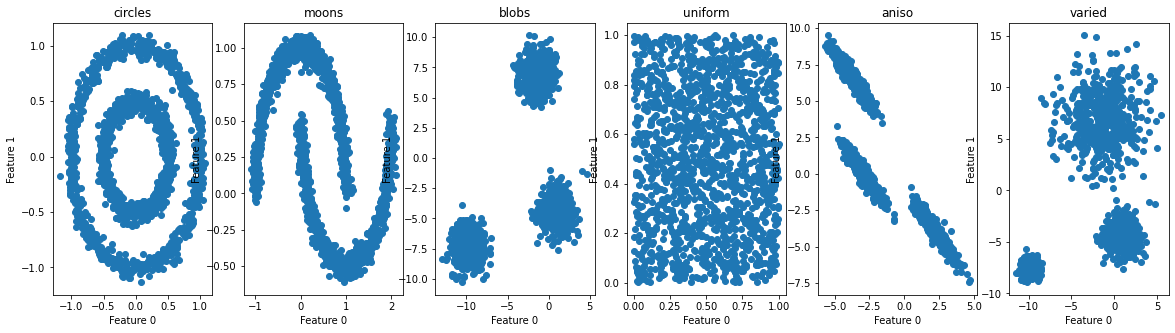

In [83]:
datsets = {'circles': noisy_circles,'moons': noisy_moons,'blobs': blobs,'uniform': no_structure,'aniso': aniso,'varied': varied}
plot_nr = 1
plt.figure(figsize=(20, 5))
for key in datsets:
    X, y = datsets[key]
    plt.subplot(1, len(datsets), plot_nr)
    plt.scatter(X[:, 0], X[:, 1])
    plt.xlabel('Feature 0')
    plt.ylabel('Feature 1')
    plt.title(label=key)
    plot_nr += 1

# KMeans - кластерирање според точки на рамнотежа
KMeans алгоритмот применува пристап на оптимално поставување на точки на рамнотежа. Секоја точка од податочното множество припаѓа на соодветен кластер во зависност од растојанието до секоја од рамнотежните точки. Бројот на рамнотежни точки е еквивалентен на бројот на кластер кои ги дефинира самиот корисникот. Алгоритмот на оптимизација е итеративен и има неконвексна функција на цена. Работи на принципот на случајно иницијализирање на рамнотежни точки кои тежнее да ги приближи кон соодветната група на податочни точки која би можела да се карактеризира како еден кластер. За жал алгоритмот тежнее да бара кластери дури и кога множество е униформно. Имено, доколку корисникот дефинира KMeans модел со $n$ кластери, тогаш моделот ќе ги пронајде тие кластери дури и кога не постојат (множеството е униформно). Поради тоа што функцијата на цена е неконвексна многу често алгоритмот тежнее да конвергира во локален минимум. Според тоа, потребно е да се користат соодветни методи за иницијализација на рамнотежните точки како KMeans++. Предностите и недостатоците на KMeans можат да се сублимираат во следната табела:

|Предности|Недостатоци|
|---|---|
|Едноставен за имплементација|Бројот на кластери мора однапред да се определи|
|Може да се применува за големи податочни множества|Решението зависи од инцијализацијата на алгоритмот(неконвексна функција на цена)|
|Наоѓа кластери дури и кога нивното постоење не е очигледно(во некои случаи ова е недостаток)|Потфрлува кај множества со многу шум (outliers)|
|Паралелизација на алгоритмот за извршување на повеќе процесори|Потфрлува да најде кластери кои имаат специфична форма|

Клучни параметри кај KMeans:
* **n_clusters:** број на кластери кои е потребно да ги најде моделот. Опсег на целобројни вредности: **[0, inf]**
* **init:** метода на иницијализација на рамнотежни точки. Множество на вредности: **['auto', 'kmeans++']** или рачно зададени координати за секоја рамнотежна точка.
* **n_init:** колку пати одново да се истренира моделот за различни иницијални вредности на рамнотежните точки. Се бира оној модел во онаа итерација каде имал најниска функција на цена.

## Утврдување на број на кластери според elbow method
Еден од недостатоците на KMeans  е тоа што корисникот однапред треба да го познава бројот на кластери кои треба да ги најде моделот. Во случаеви кога корисникот не го познава бројот на потребни кластери кои треба да ги најде моделот, возможно е да се користат методи за кои самите ќе го определат овој број. Една од овие метода е методата на прекршочна точка (Elbow method). За дадените податочни множества од погоре ќе сметаме дека не го знаеме бројот на потребни кластери и последователно ќе ја примениме методата на прекршочна точка.

**За ентузијасти: истражете за тоа како функционираат декоратори (function decorators) во програмскиот јазик пајтон и обидете се да го разберете кодот во следните три ќелии**

In [4]:
def multiple_datasets(func):
    def execution_function(datsets, plot=False):
        if plot==True:
            plt.figure(figsize=(30, 10))
            plot_nr = 1
        for key in datsets:
            if plot==True:
                plt.subplot(1, len(datsets), plot_nr)
                plot_nr += 1
                
            func(key, datsets[key])
    return execution_function

In [5]:
@multiple_datasets
def kmeans_elbow_method(name, datset):
    max_nr_clusters = 15
    X, y = datset
    cost_func = []
    for nr_clusters in range(1, max_nr_clusters + 1):
        scaler = StandardScaler()
        kmeans = KMeans(n_clusters=nr_clusters, init='random', n_init=5)
        kmeans.fit(scaler.fit_transform(X))
        cost_func.append(kmeans.inertia_)

    plt.plot(range(1, 16), cost_func)
    plt.xlabel('number of clusters')
    plt.ylabel('Distortion')
    plt.xticks(range(1, 16))
    plt.grid()
    plt.title(label=name)

In [6]:
import warnings
def warn(*args, **kwargs):
    pass
warnings.warn = warn

### Ја исцртуваме функцијата на цена за различен број на кластер [1, 15] за секое од 5-те податочни множества

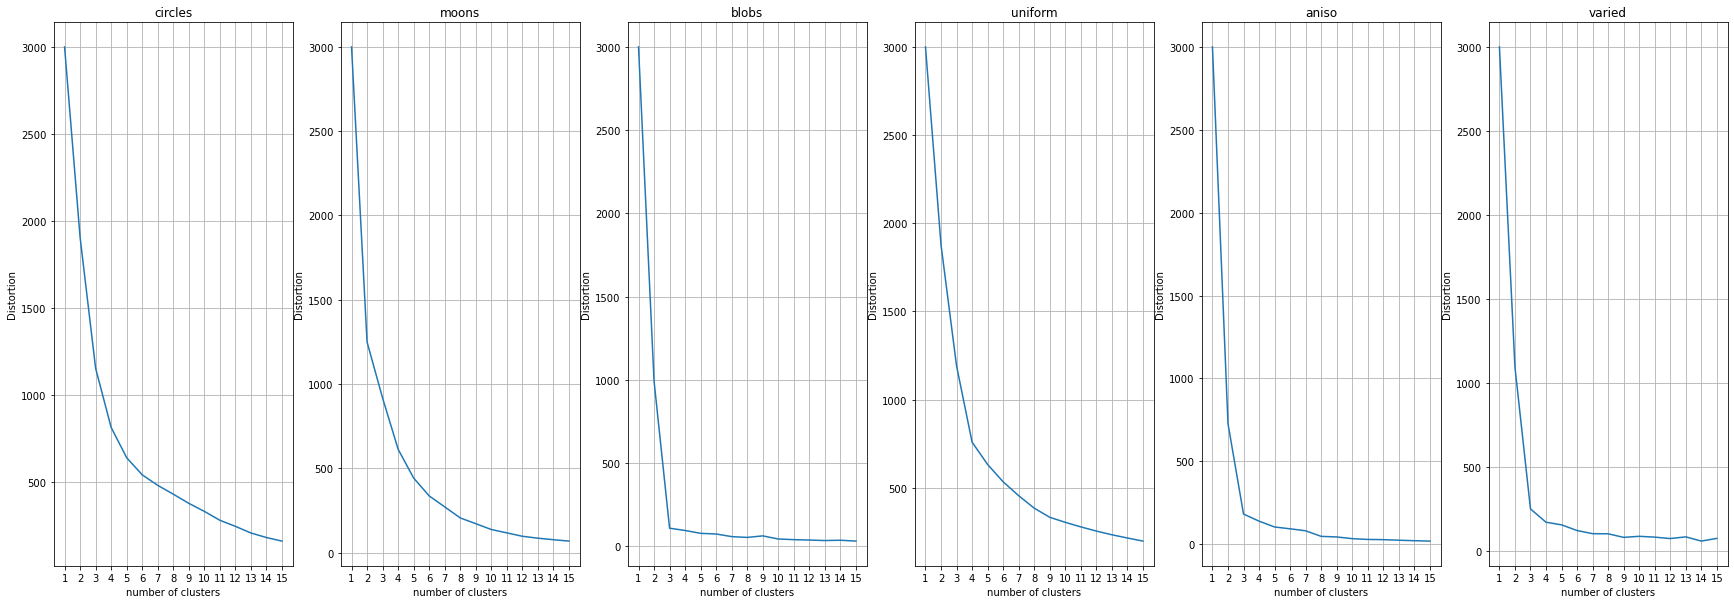

In [7]:
kmeans_elbow_method(datsets, plot=True)

Од графиците можеме да забележиме дека некои множества немаат „очигледна“ прекршочна точка и од тука може да се забележи еден од недостатоците на овој алгоритам. Овој проблем може да се воочи кај податочните множества: circles, moons, uniform. Поради специфичната форма на некои кластери во податочните множества, методата на утврдување на прекршочна точка не помага во дефинирање на параметарот за број на кластери. Поради тоа, кај вакви множества, доколку предходно не е познат бројот на кластер, оваа метода не е апликативна.

Од друга страна, кај оние множества кои имаат очигледно раздвојливи групи на податочни точки со свои точки на рамнотежа, бројот на кластери може многу лесно да се дефинира бидејќи прекршочната точка е очигледна во графикот. Ваков е примерот за податочното множество blobs, aniso и varied.

Од тука ќе ги дефинираме следните параметри за бројот на кластери од секое податочно множество:

In [8]:
nrs_clusters = {'circles': 3, 'moons': 2, 'blobs': 3, 'uniform': 4, 'aniso': 3, 'varied': 3}

### Тренирање на модел на KMeans за секое од податочните множества и визуелизација на резултатите

In [9]:
@multiple_datasets
def kmeans_viz(name, datset):
    X, y = datset
    scaler = StandardScaler()
    kmeans = KMeans(n_clusters=nrs_clusters[name], 
                    init='random', 
                    n_init=5)
    
    
    y_pred = kmeans.fit_predict(scaler.fit_transform(X))
    plt.scatter(X[:, 0], X[:, 1], c=y_pred)
    
    
    plt.xlabel('Feature 0')
    plt.ylabel('Feature 1')
    plt.title(label=name)

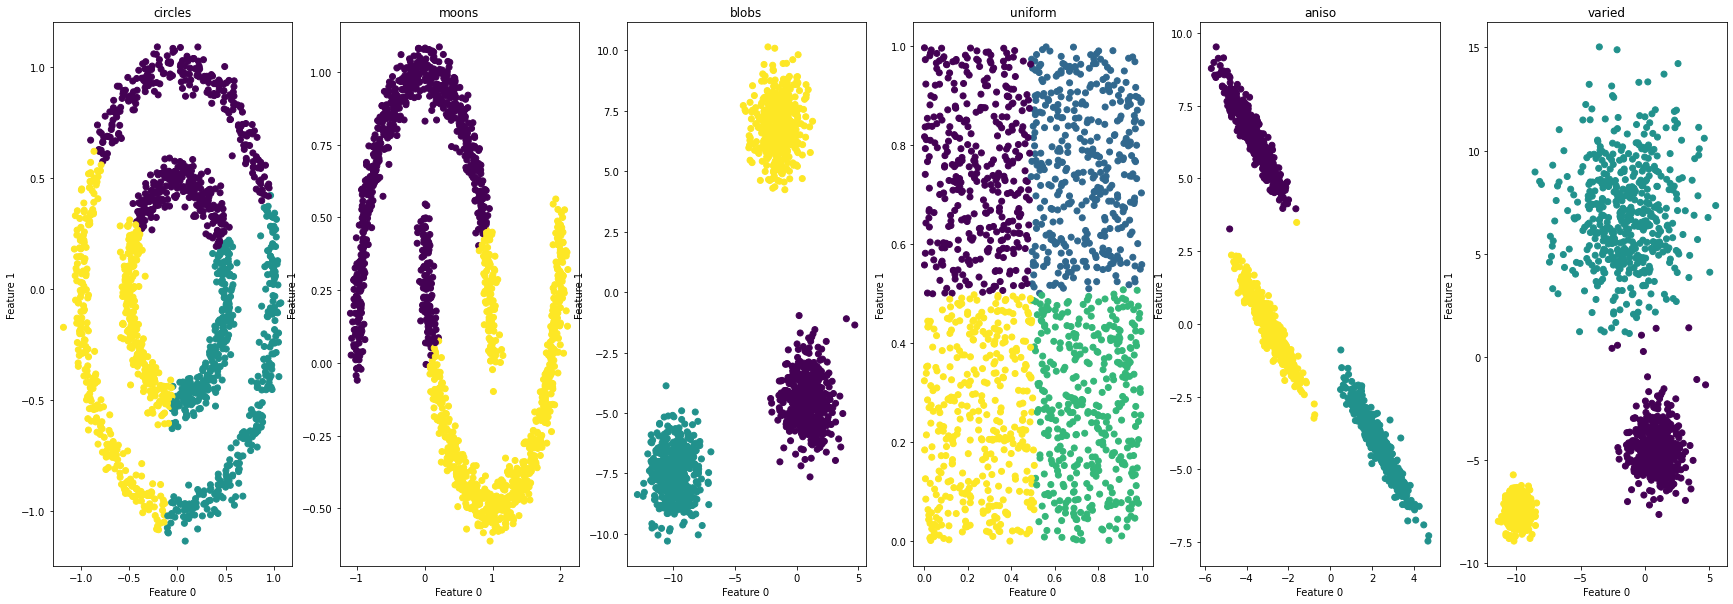

In [10]:
kmeans_viz(datsets, plot=True)

Од резултатите може да се заклучи дека KMeans  потфрлува кај податочни множества чии графици од методата на прекршочна точка се двосмислени. Имено, KMeans во вакви случаи потфрлува да ги најде вистинските кластери. Понатамошно, може да се увиди дека методата тежнее да најде кластери дури и кога тие не постојат, како во примерот на податочното множество uniform.

# DBSCAN
DBSCAN претставува алгоритам на кластерирање кој ја користи густината помеѓу точките за да најде соодветен кластер. Ова го применува на тој начин така што предходно корисникот дефинира радиус на кружница(eps) и минимален број на точки(min_samples) за да може истите да дефинираат припадност на еден кластер. Доколку определена точка е доволно далеку од очигледните кластери формирани со помош на параметри eps и min_samples, тогаш таа се означува како отпадник (outlier). Отпадниците во DBSCAN добиваат вредност -1 при предвидувањето, којашто означува дека податочната точка не припаѓа на ниту еден кластер. За разлика од KMeans, DBSCAN не побарува предходно дефинирање на бројот на кластери и неговите предности и недостатоци може да се сумираат во следната табела:

|Предности|Недостатоци|
|---|---|
|Не е потребно предходно определување на бројот на кластери|Невозможна е паралелизација на алгоритмот за работа на повеќе процесори|
|Може да наоѓа кластери со специфични форми|Повеќе параметри за нагодување|
|Робусен во случаи на шум(outliers)|Лоши резултати во случаи на лошо нагодени параметри|
||Потфрлува да најде кластери кога различни групи на податочни точки имаат променлива густина|

Клучни параметри кај DBSCAN:
* **eps:** Го дефинира радиусот на кружница околу една точка за кој сите податочни точки во кружницата ќе се сметаат за соседи. Сите точки надвор од кружницаата се сметаат за отпадници (outliers). Ако овој параметар е избран да биде многу мал, тогаш голем дел од податоците ќе бидат предвидени како отпадници (outliers). Доколку овој параметар е многу голем тогаш кластерите ќе се спојат и мноштвото од податочните точки ќе припаѓаат на само еден кластер. Еден начин за наоѓање на овој параметар е да се примени k-distance graph. Опсег на реални вредности: **[0, inf]**
* **min_samples:** минимален број на соседи (податочни точки) кои се наоѓаат во кружницата со радиус eps, за да формираат еден кластер. За поголеми податочни множества треба да се користат поголеми вредности за овој параметар. Општо правило може да се земе дека $min\_samples \geq D + 1$ каде $D$ е бројот на колони во податочното множество.

Погледнете го следното [видео](https://www.youtube.com/watch?v=RDZUdRSDOok&t=61s) за повеќе детали околу принципот на работa на DBSCAN.

### Тренирање на модел на DBSSCAN за секое од податочните множества и визуелизација на резултатите

In [11]:
@multiple_datasets
def DBSCAN_viz(name, datset):
    X, y = datset
    scaler = StandardScaler()
    dbscan = DBSCAN(eps=0.3, 
                    min_samples=10)
    
    y_pred = dbscan.fit_predict(scaler.fit_transform(X))
    plt.scatter(X[:, 0], X[:, 1], c=y_pred)
    
    
    plt.xlabel('Feature 0')
    plt.ylabel('Feature 1')
    plt.title(label=name)

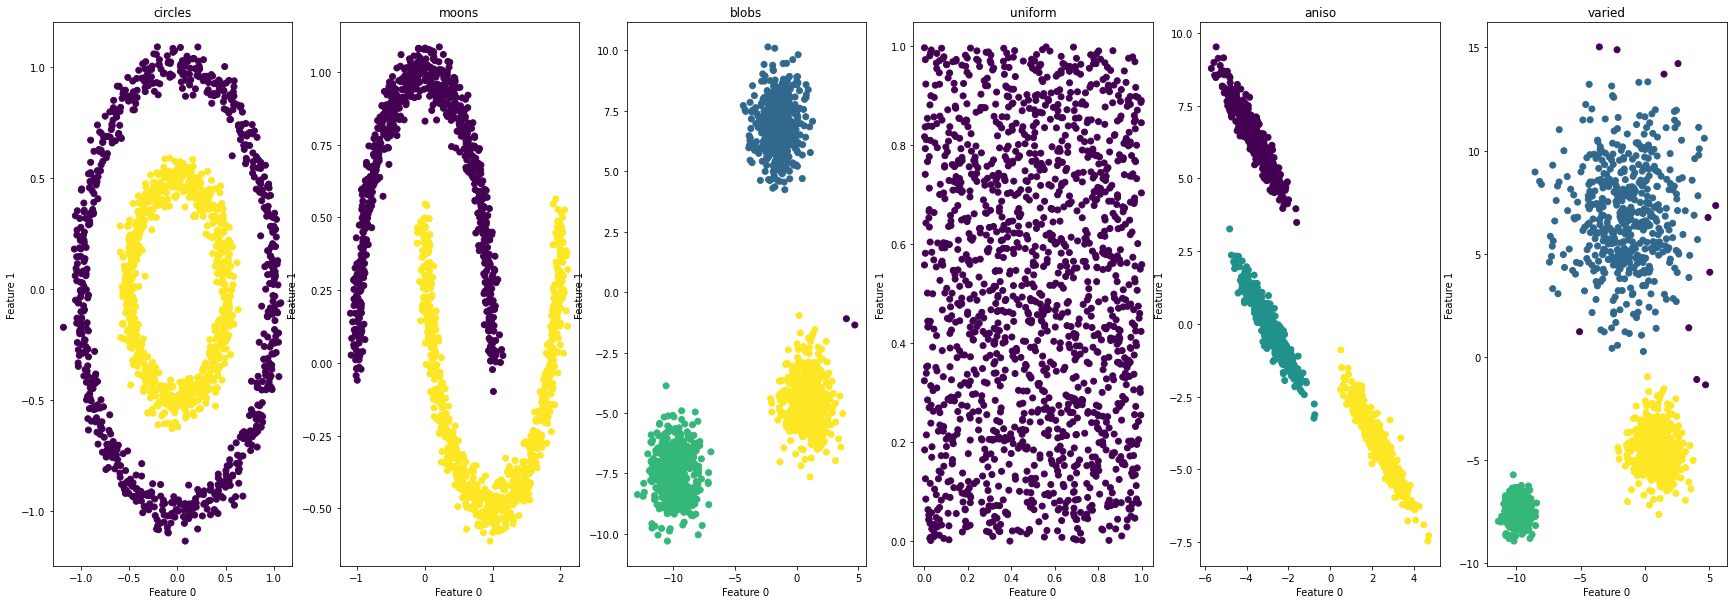

In [12]:
DBSCAN_viz(datsets, plot=True)

1. За разлика од KMeans може да се забележи дека DBSCAN успешно наоѓа ги кластерира податочните множества circles и moons.
2. Дополнително може да се забележи дека податочното множество uniform правилно го детектира како еден кластер.
3. Понатамошно може да се забележи дека податочните множества blobs и aniso се слично кластерирани како KMeans со исклучок на отпадниците (виолетовите точки).
4. Бројот на отпадници значително се зголемува во податочното множество varied  поради тоа што DBSCAN не е добар пре кластерирање на податочни множества каде различни кластери имаат различна густина.

Сепак овие резултати беа добиени за идеално нагодени параметри. Во следниот пример ќе демонстрираме резултати од DBSCAN за неидеални вредности на параметрите.

### Тренирање на модел на DBSSCAN за секое од податочните множества и визуелизација на резултатите (неидеални параметри)

In [105]:
@multiple_datasets
def DBSCAN_viz(name, datset):
    X, y = datset
    scaler = StandardScaler()
    dbscan = DBSCAN(eps=0.1, 
                    min_samples=10)
    
    y_pred = dbscan.fit_predict(scaler.fit_transform(X))
    plt.scatter(X[:, 0], X[:, 1], c=y_pred)
    
    plt.xlabel('Feature 0')
    plt.ylabel('Feature 1')
    plt.title(label=name)

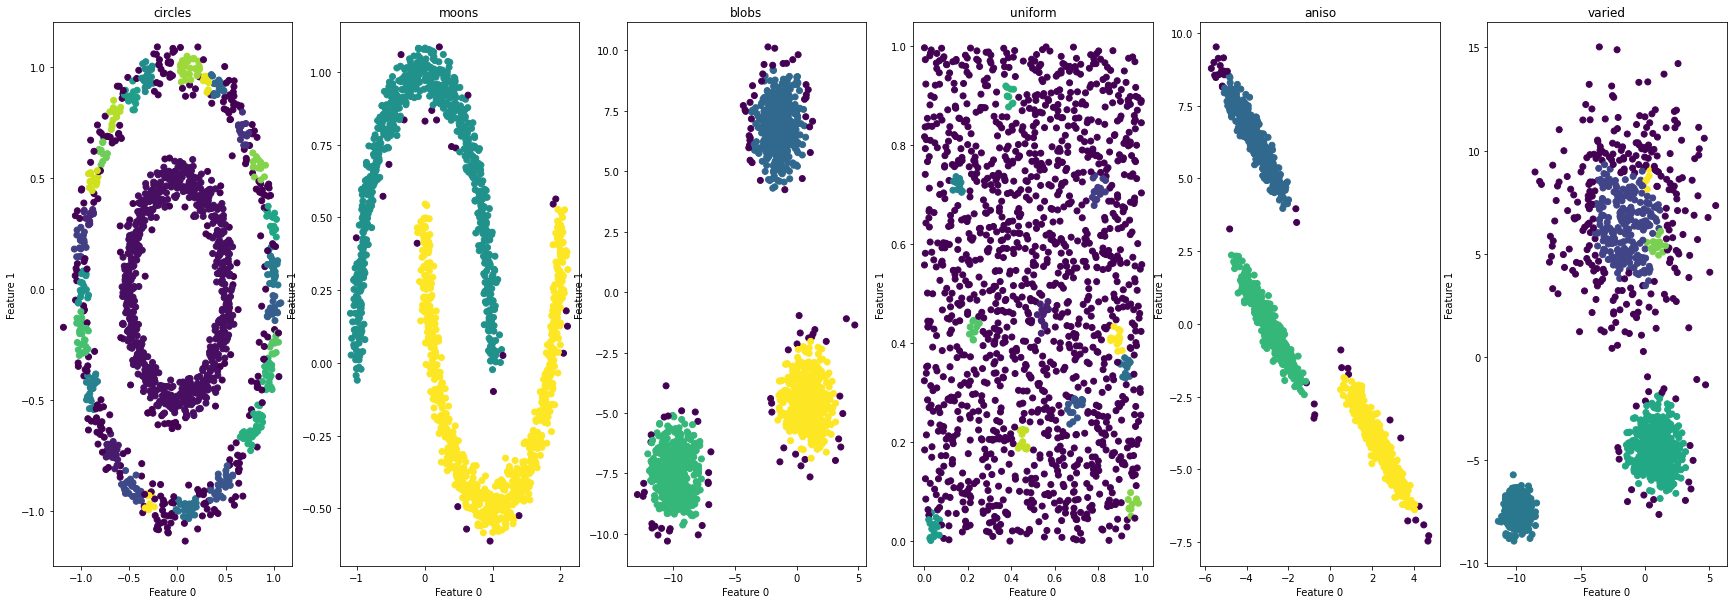

In [106]:
DBSCAN_viz(datsets, plot=True)

Обидете се да го тестирате алгоритмот за следниве вредности на параметрите и оценете ја неговата работа во вакви случаи {eps, min_samples}:
* {0.1, 10}
* {0.5, 10}
* {1, 10}
* {0.3, 2}
* {0.3, 100}

Поради сензитивноста на резултатите на алгоритмот во зависност од неговите параметри, примената на овој алгоритам секогаш мора да биде поткрепена со добро познавање на податочното множество врз кое се имплементира.

# Кластерирање на метеоролошки станици според климатски карактеристики
Во оваа вежба се ќе искористиме податочно множество од метеоролошки станици заедно со некои карактеристики изведени од нивните мерењa на територијата на Канада. Кластерирањето ќе go направиме според климата, а потоа географски ќе ги визуелизираме станиците за да ја процениме постапката. За оваа вежба ќе ви бидат потребни следните библиотеки:
1. wget -> (conda install -c conda-forge python-wget)
2. cartopy -> (conda install -c conda-forge cartopy)
3. PIL -> (conda install -c anaconda pillow)

Станиците ќе бидат прикажани на исцртана мапа, па за таа намена ќе ја искористиме Cartopy дополнителната алатка за matplotlib.

**Информации за податочното множество:**
<h4 align = "center">
Environment Canada    
Monthly Values for July - 2015	
</h4>
<html>
<head>
<style>
table {
    font-family: arial, sans-serif;
    border-collapse: collapse;
    width: 100%;
}

td, th {
    border: 1px solid #dddddd;
    text-align: left;
    padding: 8px;
}

tr:nth-child(even) {
    background-color: #dddddd;
}
</style>
</head>
<body>

<table>
  <tr>
    <th>Name in the table</th>
    <th>Meaning</th>
  </tr>
  <tr>
    <td><font color = "green"><strong>Stn_Name</font></td>
    <td><font color = "green"><strong>Station Name</font</td>
  </tr>
  <tr>
    <td><font color = "green"><strong>Lat</font></td>
    <td><font color = "green"><strong>Latitude (North+, degrees)</font></td>
  </tr>
  <tr>
    <td><font color = "green"><strong>Long</font></td>
    <td><font color = "green"><strong>Longitude (West - , degrees)</font></td>
  </tr>
  <tr>
    <td>Prov</td>
    <td>Province</td>
  </tr>
  <tr>
    <td>Tm</td>
    <td>Mean Temperature (°C)</td>
  </tr>
  <tr>
    <td>DwTm</td>
    <td>Days without Valid Mean Temperature</td>
  </tr>
  <tr>
    <td>D</td>
    <td>Mean Temperature difference from Normal (1981-2010) (°C)</td>
  </tr>
  <tr>
    <td><font color = "black">Tx</font></td>
    <td><font color = "black">Highest Monthly Maximum Temperature (°C)</font></td>
  </tr>
  <tr>
    <td>DwTx</td>
    <td>Days without Valid Maximum Temperature</td>
  </tr>
  <tr>
    <td><font color = "black">Tn</font></td>
    <td><font color = "black">Lowest Monthly Minimum Temperature (°C)</font></td>
  </tr>
  <tr>
    <td>DwTn</td>
    <td>Days without Valid Minimum Temperature</td>
  </tr>
  <tr>
    <td>S</td>
    <td>Snowfall (cm)</td>
  </tr>
  <tr>
    <td>DwS</td>
    <td>Days without Valid Snowfall</td>
  </tr>
  <tr>
    <td>S%N</td>
    <td>Percent of Normal (1981-2010) Snowfall</td>
  </tr>
  <tr>
    <td><font color = "green"><strong>P</font></td>
    <td><font color = "green"><strong>Total Precipitation (mm)</font></td>
  </tr>
  <tr>
    <td>DwP</td>
    <td>Days without Valid Precipitation</td>
  </tr>
  <tr>
    <td>P%N</td>
    <td>Percent of Normal (1981-2010) Precipitation</td>
  </tr>
  <tr>
    <td>S_G</td>
    <td>Snow on the ground at the end of the month (cm)</td>
  </tr>
  <tr>
    <td>Pd</td>
    <td>Number of days with Precipitation 1.0 mm or more</td>
  </tr>
  <tr>
    <td>BS</td>
    <td>Bright Sunshine (hours)</td>
  </tr>
  <tr>
    <td>DwBS</td>
    <td>Days without Valid Bright Sunshine</td>
  </tr>
  <tr>
    <td>BS%</td>
    <td>Percent of Normal (1981-2010) Bright Sunshine</td>
  </tr>
  <tr>
    <td>HDD</td>
    <td>Degree Days below 18 °C</td>
  </tr>
  <tr>
    <td>CDD</td>
    <td>Degree Days above 18 °C</td>
  </tr>
  <tr>
    <td>Stn_No</td>
    <td>Climate station identifier (first 3 digits indicate   drainage basin, last 4 characters are for sorting alphabetically).</td>
  </tr>
  <tr>
    <td>NA</td>
    <td>Not Available</td>
  </tr>


</table>

</body>
</html>

In [66]:
import wget
import cartopy.crs as ccrs
import cartopy
from sklearn.cluster import KMeans, DBSCAN
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import pandas as pd

In [67]:
wget.download('https://s3-api.us-geo.objectstorage.softlayer.net/cf-courses-data/CognitiveClass/ML0101ENv3/labs/weather-stations20140101-20141231.csv')

100% [............................................................................] 129821 / 129821

'weather-stations20140101-20141231 (3).csv'

## Вчитување на податоците

1. Со помош на библиотеката pandas, сместете ги податоците во променлива по име data
2. Прикажете ги првите 5 редици од прочитаната табела
3. Прикажете општи информации за прочитаните податоци како: податочен тип на секоја колона (feature), број на non-null редици за секоја колона, име на колона, итн.
4. Прикажете општи статистички метрики за секоја од колоните.

**помош: read_csv(), head(), info(), describe(), .columns**

In [68]:
data = pd.read_csv('weather-stations20140101-20141231.csv')

## Прочистување на податочното множество

### Отстранете ги сите колони кои содржат повеќе од 300 NaN вредности

**помош: ['BS', 'DwBS', 'BS%', 'D', 'S', 'DwS', 'S%N', 'P%N', 'S_G']; pandas.*.drop(?)**

### На предходно прочистеното множество отстранете ги сите редици кои содржат NaN вредности

**помош: pandas.*.dropna(?)**

### Проверете дали множеството е прочистено од NaN вредности

**помош: pandas.*.info()**

## Географска визуелизација на станиците
Извршете ја ќелијата за да ги визуелизирате станиците каде се простираат географски.

In [ ]:
coords = data[['Long', 'Lat']]
extent = [-140, -50, 40, 65]

plt.figure(figsize=(14, 10))
ax = plt.axes(projection=ccrs.PlateCarree())
ax.coastlines()
ax.stock_img()
ax.set_extent(extent)
ax.add_feature(cartopy.feature.LAND)
ax.add_feature(cartopy.feature.OCEAN)
ax.add_feature(cartopy.feature.COASTLINE)
ax.add_feature(cartopy.feature.LAKES)
ax.add_feature(cartopy.feature.RIVERS)
ax.add_feature(cartopy.feature.BORDERS)
ax.scatter(coords['Long'], coords['Lat'], transform=ccrs.PlateCarree(), color='r', s=10)
plt.show()

### Отстранете ги сите колони кои не се поврзани со климата

Целта е да направиме кластерирање на метеоролошките станици според климатските податоци. Доколку во нашето податочно множество постојат колони кои не се поврзани со климата моделот може да потфрли. За таа намена потребно е да ги отсраниме сите колони кои не се поврзани со климата како: ['Long', 'Lat', 'Stn_No', 'Stn_Name', 'Prov'].

**помош: pandas.*.drop(?)**

# Кластерирање (KMeans)

### Применете метода на прекршочна точка за да го определите бројот на кластери

**помош: погледнете ја ќелијата од погоре за метода на прекршочна точка**

## Дали е потребно да се изврши стандардизација на податоците пред да се тренира моделот?
KMeans моделот работи на принцип на пресметка на евклидово растојание помеѓу податочните точки. Да претпоставиме дека го имаме следното податочно множество:

|Р. бр.|Возраст|Годишен приход (мкд)|
|-|-|-|
|1|22|300.000|
|2|30|600.000|
|3|32|420.000|
|4|45|1.000.000|
|5|45|300.000|

Од податочното множество може да се воочи дека возраста се менува во опсегот [22, 45] додека приходот се менува во опсег од [300.000, 1.000.000]. Доколку сакаме да го пресметаме евклидовото растојание помеѓу точка 4 и точка 1 тогаш тоа ќе биде:

$$L_{41} = \sqrt{(45 - 22)^2 + (1000.000 - 300.000)^2} = 700.000,000377$$

Доколку сакаме да го пресметаме евклидовото растојание помеѓу точка 5 и точка 4 тогаш тоа ќе биде:

$$L_{54} = \sqrt{(45 - 45)^2 + (300.000 - 1000.000)^2} = 700.000$$

Може да се воочи дека покрај тоа што примерокот бр. 5 е скоро два пати постар од примерокот бр. 1, сепак евклидовото растојание остана приближно исто. Причината за ова е бидејќи колоната за годишен приход е доминантна при пресметка на евклидовото растијание, поради тоа што истата прима многу поголеми вредности во однос колоната за возраст. Според тоа, доколку податочното множество не се стандардизира, најголемо влијание при кластерирање ќе имаат оние колони кои имаат поголеми опсези на вредности.

Овој проблем може да се надмине доколку податочното множество се стандардизира. Истото податочно множество од горе е прикажано во следната табела во стандардизирана форма:

|Р. бр.|Возраст|Годишен приход (мкд)|
|-|-|-|
|1|-1.42|-0.85|
|2|-0.53|0.28|
|3|-0.31|-0.39|
|4|1.13|1.81|
|5|1.13|-0.85|

Доколку сакаме да го пресметаме евклидовото растојание помеѓу точка 4 и точка 1 тогаш тоа ќе биде:

$$L_{s41} = \sqrt{(1.13 - (-1.42))^2 + (1.81 - (-0.85))^2} = 3,68$$

Доколку сакаме да го пресметаме евклидовото растојание помеѓу точка 5 и точка 4 тогаш тоа ќе биде:

$$L_{s54} = \sqrt{(1.13 - 1.13)^2 + (-0.85 - 1.81)^2} = 2,66$$

Сега можеме да забележиме дека разликата во евклидовото растојание е драстично различна во споредба со случајот кога податоците не се стандардизирани

**Забелешка:** Стандардизација треба да се избегнува за колони кај кои пости заемна релација. Таков пример би биле колони за географски координати како: географска должина и ширина. Доколку овие колони се стандардизираат тогаш ќе настане дисторзија во нивните вредности и при тоа ќе се изгуби заемната релација.

### Стандардизирајте го податочното множество

**помош: kmeans.*.StandardScaler()**

### Истренирајте KMeans модел за следните параметри:

* **n_clusters:** 3
* **init:** 'k-means++'
* **n_init:** 20

**помош:sklearn.*.KMeans(?)**

### Сместете ја припадноста на кластерот за секоја податочна точка во променлива y_pred
y_pred = kmeans.fit_predict(data_scaled)
**помош: KMeans.*.fit_predict(?)**

### Географска визуелизација на припадноста на кластери за секоја метео. станица
Извршете ја ќелијата за да ги визуелизирате станиците каде се простираат географски и која е нивната припадност кон трите кластери.

In [ ]:
extent = [-140, -50, 40, 65]

plt.figure(figsize=(14, 10))
ax = plt.axes(projection=ccrs.PlateCarree())
ax.coastlines()
ax.stock_img()
ax.set_extent(extent)
ax.add_feature(cartopy.feature.LAND)
ax.add_feature(cartopy.feature.OCEAN)
ax.add_feature(cartopy.feature.COASTLINE)
ax.add_feature(cartopy.feature.LAKES)
ax.add_feature(cartopy.feature.RIVERS)
ax.add_feature(cartopy.feature.BORDERS)
ax.scatter(coords['Long'], coords['Lat'], transform=ccrs.PlateCarree(), c=y_pred, s=10)
plt.show()

Доколку се игнорираат станиците во северниот дел на државата, може да се забележи дека кластерирањето според климатските карактеристики доведува до кластери кои се распределени според блискоста до океан. Сепак, поради двосмисленоста на графикот на прекршочна точкa, со добро нагодени параметри, DBSCAN можеби би била подобра опција.

### За дома: истренирајте модел на DBSCAN за истото податочно множество и споредете ги резултатите со KMeans